In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import sys

from pathlib import Path

from sklearn.model_selection import (
    StratifiedGroupKFold,
    cross_validate
)

sys.path.insert(0, str(Path("..").resolve()))

from src.train_models import create_models

RANDOM_STATE = 42

sns.set_theme(style="whitegrid")

In [2]:
DATA_DIR = Path("../data/processed")
RESULT_DIR = Path("../reports/results")
FIGURE_DIR = Path("../reports/figures")

RESULT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Directories configured successfully!")

Directories configured successfully!


In [3]:
X_train = pd.read_csv(
    DATA_DIR / "X_train.csv"
)

y_train = pd.read_csv(
    DATA_DIR / "y_train.csv"
)["label"]

print("Training Features:", X_train.shape)
print("Training Target:", y_train.shape)

print("\nClass Distribution:")
print(y_train.value_counts())

Training Features: (140274, 42)
Training Target: (140274,)

Class Distribution:
label
1    95474
0    44800
Name: count, dtype: int64


In [4]:
groups = pd.util.hash_pandas_object(
    X_train,
    index=False
).to_numpy()

print("Total Records:", len(X_train))

print("Unique Feature Groups:",
      len(np.unique(groups)))

print("Repeated Feature Records:",
      len(groups) - len(np.unique(groups)))

Total Records: 140274
Unique Feature Groups: 80821
Repeated Feature Records: 59453


In [5]:
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

print("5-Fold Cross-Validation configured!")

5-Fold Cross-Validation configured!


In [6]:
fold_details = []

for fold, (train_idx, val_idx) in enumerate(
    cv.split(X_train, y_train, groups),
    start=1
):

    train_groups = set(groups[train_idx])
    val_groups = set(groups[val_idx])

    overlap = len(
        train_groups.intersection(val_groups)
    )

    fold_details.append({
        "Fold": fold,
        "Training Records": len(train_idx),
        "Validation Records": len(val_idx),
        "Normal Records": (
            y_train.iloc[val_idx] == 0
        ).sum(),
        "Malicious Records": (
            y_train.iloc[val_idx] == 1
        ).sum(),
        "Group Overlap": overlap
    })

    assert overlap == 0

fold_details_df = pd.DataFrame(fold_details)

display(fold_details_df)

,Fold,Training Records,Validation Records,Normal Records,Malicious Records,Group Overlap
0,1,112220,28054,8960,19094,0
1,2,112219,28055,8960,19095,0
2,3,112219,28055,8960,19095,0
3,4,112219,28055,8960,19095,0
4,5,112219,28055,8960,19095,0


In [7]:
models = create_models(
    X_train,
    random_state=RANDOM_STATE
)

for name in models:
    print(f"{name} created successfully!")

Logistic Regression created successfully!
Decision Tree created successfully!
Random Forest created successfully!


In [8]:
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

print("Evaluation metrics configured!")

Evaluation metrics configured!


In [9]:
cv_results = {}

for name, model in models.items():

    print(f"\nCross-validating {name}...")

    start_time = time.perf_counter()

    scores = cross_validate(
        estimator=model,
        X=X_train,
        y=y_train,
        groups=groups,
        cv=cv,
        scoring=scoring,
        n_jobs=1,
        return_train_score=True,
        error_score="raise"
    )

    elapsed_time = time.perf_counter() - start_time

    cv_results[name] = scores

    print(f"{name} completed successfully!")

    print(f"Mean Accuracy: "
          f"{scores['test_accuracy'].mean():.4f}")

    print(f"Mean F1 Score: "
          f"{scores['test_f1'].mean():.4f}")

    print(f"Execution Time: {elapsed_time:.2f} seconds")

print("\nAll cross-validation processes completed!")


Cross-validating Logistic Regression...
Logistic Regression completed successfully!
Mean Accuracy: 0.9349
Mean F1 Score: 0.9538
Execution Time: 68.74 seconds

Cross-validating Decision Tree...
Decision Tree completed successfully!
Mean Accuracy: 0.9379
Mean F1 Score: 0.9542
Execution Time: 83.39 seconds

Cross-validating Random Forest...
Random Forest completed successfully!
Mean Accuracy: 0.9534
Mean F1 Score: 0.9661
Execution Time: 482.49 seconds

All cross-validation processes completed!


In [12]:
fold_results = []

for name, scores in cv_results.items():

    for fold in range(5):

        fold_results.append({
            "Model": name,
            "Fold": fold + 1,
            "Accuracy": scores["test_accuracy"][fold],
            "Precision": scores["test_precision"][fold],
            "Recall": scores["test_recall"][fold],
            "F1 Score": scores["test_f1"][fold],
            "ROC AUC": scores["test_roc_auc"][fold]
        })

fold_results_df = pd.DataFrame(fold_results)

display(fold_results_df.round(4))

,Model,Fold,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Logistic Regression,1,0.9355,0.9223,0.9885,0.9542,0.9833
1,Logistic Regression,2,0.9349,0.9218,0.9881,0.9538,0.9838
2,Logistic Regression,3,0.9378,0.9253,0.9884,0.9558,0.9849
3,Logistic Regression,4,0.9320,0.9194,0.9866,0.9518,0.9841
4,Logistic Regression,5,0.9343,0.9212,0.9880,0.9534,0.9835
5,Decision Tree,1,0.9358,0.9575,0.9477,0.9526,0.9303
6,Decision Tree,2,0.9399,0.9582,0.9532,0.9557,0.9335
7,Decision Tree,3,0.9404,0.9591,0.9531,0.9561,0.9341
8,Decision Tree,4,0.9378,0.9551,0.9534,0.9543,0.9297
9,Decision Tree,5,0.9354,0.9535,0.9515,0.9525,0.9281


In [11]:
summary = []

for name, scores in cv_results.items():

    summary.append({
        "Model": name,

        "Mean Accuracy":
            scores["test_accuracy"].mean(),

        "Accuracy Std":
            scores["test_accuracy"].std(),

        "Mean Precision":
            scores["test_precision"].mean(),

        "Mean Recall":
            scores["test_recall"].mean(),

        "Mean F1 Score":
            scores["test_f1"].mean(),

        "F1 Std":
            scores["test_f1"].std(),

        "Mean ROC AUC":
            scores["test_roc_auc"].mean(),

        "Mean Fit Time":
            scores["fit_time"].mean()
    })

cv_summary_df = pd.DataFrame(summary)

cv_summary_df = cv_summary_df.sort_values(
    by="Mean F1 Score",
    ascending=False
).reset_index(drop=True)

display(cv_summary_df.round(4))

,Model,Mean Accuracy,Accuracy Std,Mean Precision,Mean Recall,Mean F1 Score,F1 Std,Mean ROC AUC,Mean Fit Time
0,Random Forest,0.9534,0.0009,0.9567,0.9757,0.9661,0.0007,0.9922,86.9320
1,Decision Tree,0.9379,0.0021,0.9567,0.9518,0.9542,0.0015,0.9311,10.9414
2,Logistic Regression,0.9349,0.0019,0.9220,0.9879,0.9538,0.0013,0.9839,5.2325


In [13]:
overfitting_results = []

for name, scores in cv_results.items():

    train_accuracy = scores[
        "train_accuracy"
    ].mean()

    val_accuracy = scores[
        "test_accuracy"
    ].mean()

    overfitting_results.append({
        "Model": name,
        "Training Accuracy": train_accuracy,
        "Validation Accuracy": val_accuracy,
        "Accuracy Gap": train_accuracy - val_accuracy
    })

overfitting_df = pd.DataFrame(
    overfitting_results
)

display(overfitting_df.round(4))

,Model,Training Accuracy,Validation Accuracy,Accuracy Gap
0,Logistic Regression,0.9353,0.9349,0.0004
1,Decision Tree,0.9981,0.9379,0.0603
2,Random Forest,0.9981,0.9534,0.0447


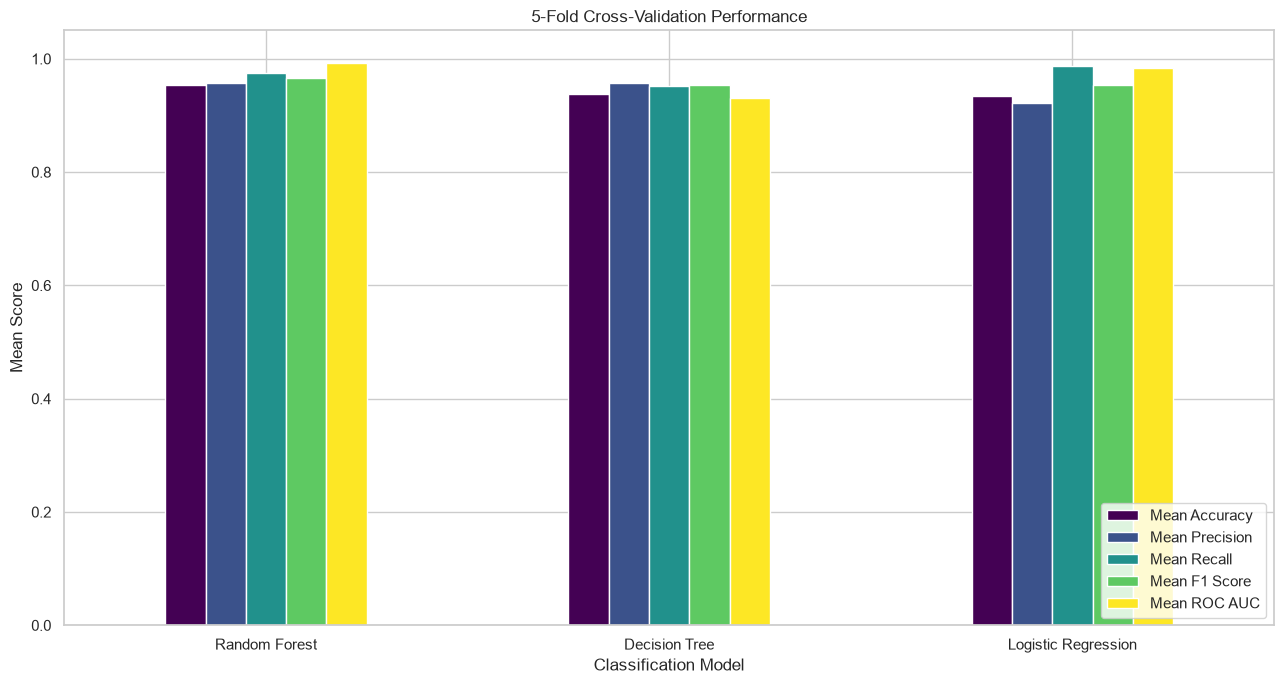

In [14]:
metrics = [
    "Mean Accuracy",
    "Mean Precision",
    "Mean Recall",
    "Mean F1 Score",
    "Mean ROC AUC"
]

cv_summary_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(13, 7),
    colormap="viridis"
)

plt.title("5-Fold Cross-Validation Performance")

plt.xlabel("Classification Model")
plt.ylabel("Mean Score")

plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower right")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "cross_validation_comparison.png",
    dpi=300
)

plt.show()

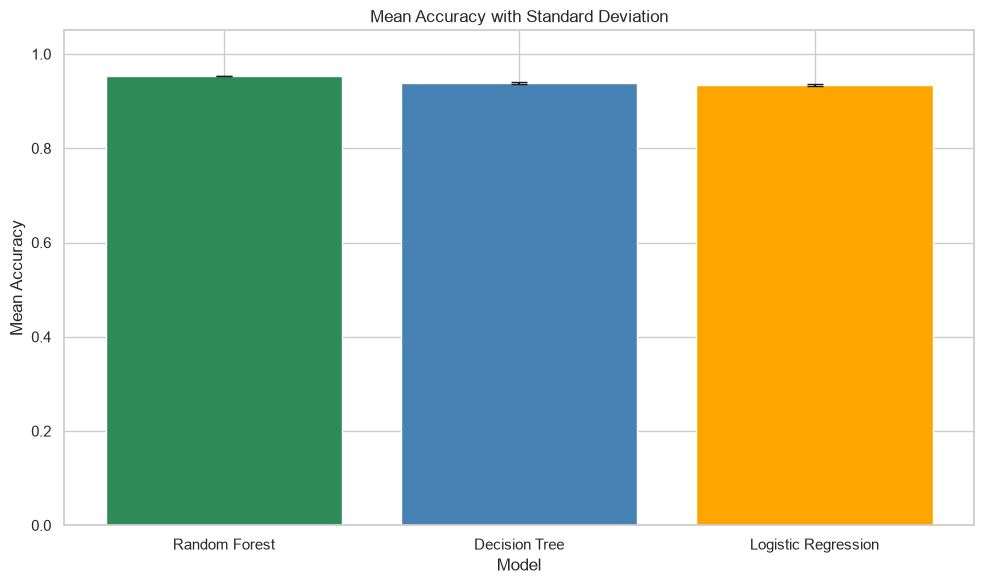

In [15]:
plt.figure(figsize=(10, 6))

plt.bar(
    cv_summary_df["Model"],
    cv_summary_df["Mean Accuracy"],
    yerr=cv_summary_df["Accuracy Std"],
    capsize=6,
    color=["seagreen", "steelblue", "orange"]
)

plt.title("Mean Accuracy with Standard Deviation")

plt.xlabel("Model")
plt.ylabel("Mean Accuracy")

plt.ylim(0, 1.05)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "cross_validation_stability.png",
    dpi=300
)

plt.show()

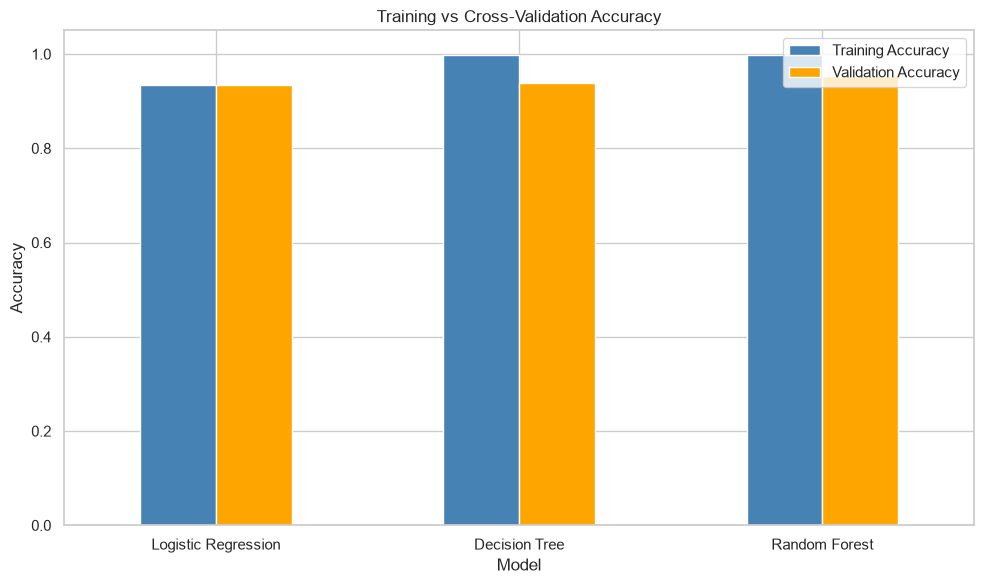

In [16]:
overfitting_df.set_index("Model")[[
    "Training Accuracy",
    "Validation Accuracy"
]].plot(
    kind="bar",
    figsize=(10, 6),
    color=["steelblue", "orange"]
)

plt.title("Training vs Cross-Validation Accuracy")

plt.ylabel("Accuracy")
plt.xlabel("Model")

plt.ylim(0, 1.05)
plt.xticks(rotation=0)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "overfitting_comparison.png",
    dpi=300
)

plt.show()

In [17]:
best_accuracy = cv_summary_df.loc[
    cv_summary_df["Mean Accuracy"].idxmax()
]

best_recall = cv_summary_df.loc[
    cv_summary_df["Mean Recall"].idxmax()
]

best_f1 = cv_summary_df.loc[
    cv_summary_df["Mean F1 Score"].idxmax()
]

most_stable = cv_summary_df.loc[
    cv_summary_df["F1 Std"].idxmin()
]

print("Highest Mean Accuracy:",
      best_accuracy["Model"])

print("Highest Mean Recall:",
      best_recall["Model"])

print("Highest Mean F1 Score:",
      best_f1["Model"])

print("Most Stable F1 Score:",
      most_stable["Model"])

Highest Mean Accuracy: Random Forest
Highest Mean Recall: Logistic Regression
Highest Mean F1 Score: Random Forest
Most Stable F1 Score: Random Forest


In [18]:
cv_summary_df.to_csv(
    RESULT_DIR / "cross_validation_results.csv",
    index=False
)

fold_results_df.to_csv(
    RESULT_DIR / "cross_validation_fold_scores.csv",
    index=False
)

fold_details_df.to_csv(
    RESULT_DIR / "cross_validation_fold_details.csv",
    index=False
)

overfitting_df.to_csv(
    RESULT_DIR / "overfitting_analysis.csv",
    index=False
)

print("All cross-validation reports saved successfully!")

All cross-validation reports saved successfully!
